In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import fftconvolve
from scipy.optimize import curve_fit, brentq

In [2]:
def gaussian_kernel(fs, sigma_ms, area=1.0, half_width_sigma=6):
    sigma = sigma_ms / 1000
    kt = np.arange(-half_width_sigma * sigma, half_width_sigma * sigma, 1 / fs)
    h = np.exp(-0.5 * (kt / sigma) ** 2)
    h *= area / (h.sum() / fs)
    return h

def make_signal(params):
    impulses = np.zeros_like(t)
    impulses[stim_idx] = 1.0
    h = gaussian_kernel(fs, **params)
    return fftconvolve(impulses, h, mode="same")

def morlet_transform(x, freqs, fs, n_cycles=5):
    W = np.empty((len(freqs), len(x)), dtype=np.complex128)
    for i, f in enumerate(freqs):
        sigma_t = n_cycles / (2 * np.pi * f)
        wt = np.arange(-4 * sigma_t, 4 * sigma_t, 1 / fs)
        psi = np.exp(2j * np.pi * f * wt) * np.exp(-0.5 * (wt / sigma_t) ** 2)
        psi /= np.sqrt(np.sum(np.abs(psi) ** 2))
        W[i] = fftconvolve(x, np.conj(psi[::-1]), mode="same")
    return W

def epoch_average_power(power, stim_idx, fs, t_pre, t_post):
    rel = np.arange(int(t_pre * fs), int(t_post * fs))
    good = stim_idx[(stim_idx + rel[0] >= 0) & (stim_idx + rel[-1] < power.shape[1])]
    epochs = np.stack([power[:, s + rel] for s in good], axis=0)
    return epochs.mean(axis=0), rel / fs

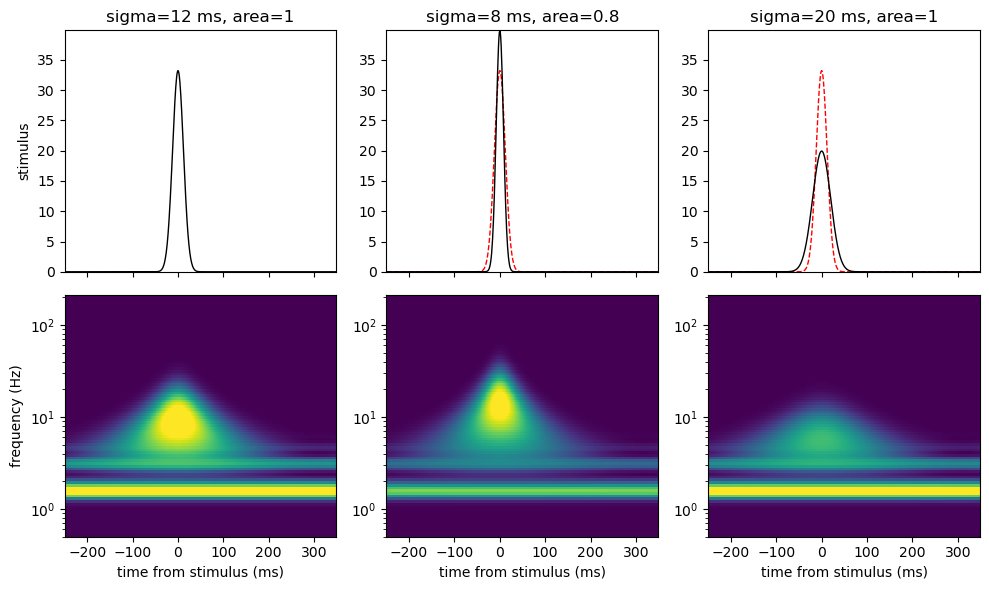

In [6]:
# Params
fs = 1000
dur = 20.0
f0 = 1.6
T = 1 / f0
t_pre, t_post = -0.25, 0.35

freqs = np.geomspace(0.5, 210, 90)
n_cycles = 5

# Condition examples
conditions = {
    'c1': {'sigma_ms': 12, 'area': 1},
    'c2': {'sigma_ms': 8, 'area': 0.8},
    'c3': {'sigma_ms': 20, 'area': 1},
}

cond_labels = {k: f'sigma={p["sigma_ms"]} ms, area={p["area"]}'
               for k, p in conditions.items()}

# Stimulus times
t = np.arange(0, dur, 1 / fs)
stim_times = np.arange(2.0, dur - 2.0, T)
stim_idx = np.round(stim_times * fs).astype(int)

# Run
results = {}
for name, params in conditions.items():
    x = make_signal(params)
    W = morlet_transform(x, freqs, fs, n_cycles)
    P = np.abs(W) ** 2
    Pav, te = epoch_average_power(P, stim_idx, fs, t_pre, t_post)
    rel = np.arange(int(t_pre * fs), int(t_post * fs))
    stim_window = x[stim_idx[0] + rel[0]:stim_idx[0] + rel[-1] + 1]
    results[name] = dict(x=x, P=P, Pav=Pav, stim_window=stim_window)

# Reference stimulus (condition 1)
ref_name = next(iter(results))
ref_window = results[ref_name]["stim_window"]

# Plot
fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex='col')

vmax = max(np.percentile(r["Pav"], 99.5) for r in results.values())
vmax *= 0.8

all_stim = np.concatenate([r["stim_window"] for r in results.values()])
ylim_stim = (all_stim.min(), all_stim.max())

for col, (name, r) in enumerate(results.items()):
    ax_top = axes[0, col]
    if col > 0:
        ax_top.plot(te * 1000, ref_window, color='red', linewidth=1, linestyle='--', label='c1')
    ax_top.plot(te * 1000, r["stim_window"], color='black', linewidth=1, label=name)
    ax_top.set_title(cond_labels[name])
    ax_top.set_xlim(te[0] * 1000, te[-1] * 1000)
    ax_top.set_ylim(ylim_stim)
    if col == 0:
        ax_top.set_ylabel('stimulus')

    ax_bottom = axes[1, col]
    ax_bottom.pcolormesh(te * 1000, freqs, r["Pav"], shading="auto", vmin=0, vmax=vmax)
    ax_bottom.set_xlabel("time from stimulus (ms)")
    ax_bottom.set_yscale("log")
    ax_bottom.set_ylim(freqs[0], freqs[-1])

axes[1, 0].set_ylabel("frequency (Hz)")
plt.tight_layout()
plt.show()

# Harmonic amplitudes
for name, params in conditions.items():
    sigma = params["sigma_ms"] / 1000
    area = params["area"]
    #print("\n", cond_labels[name])
    for k in range(1, 8):
        f = k * f0
        H = area * np.exp(-2 * np.pi**2 * sigma**2 * f**2)
        #print(f"{k}f0 = {f:4.1f} Hz: |H| = {H:.4g}")


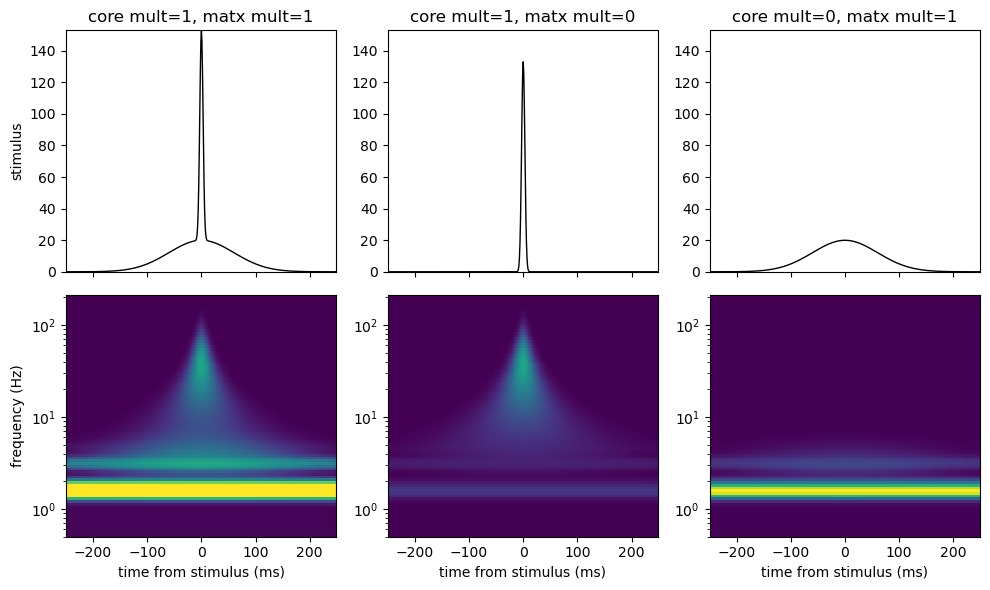

In [ ]:
# Params
fs = 1000
dur = 20.0
f0 = 1.6
T = 1 / f0
t_pre, t_post = -0.25, 0.25

freqs = np.geomspace(0.5, 210, 90)
n_cycles = 5

sigma_core = 3
sigma_matx = 60

amp_core = 1
amp_matx = 3

# Condition examples
conditions = {
    'c1': {'core': 1, 'matx': 1},
    'c2': {'core': 1, 'matx': 0},
    'c3': {'core': 0, 'matx': 1},
}

cond_labels = {k: f'core mult={p["core"]}, matx mult={p["matx"]}'
               for k, p in conditions.items()}

# Stimulus times
t = np.arange(0, dur, 1 / fs)
stim_times = np.arange(2.0, dur - 2.0, T)
stim_idx = np.round(stim_times * fs).astype(int)

# Run
results = {}
for name, params in conditions.items():
    # Generate stim trains
    x_core = amp_core * params['core'] * make_signal({'sigma_ms': sigma_core, 'area': 1})
    x_matx = amp_matx * params['matx'] * make_signal({'sigma_ms': sigma_matx, 'area': 1})
    x = x_core + x_matx

    # Spectrogram
    W = morlet_transform(x, freqs, fs, n_cycles)
    P = np.abs(W) ** 2

    # Epoch and average
    Pav, te = epoch_average_power(P, stim_idx, fs, t_pre, t_post)

    # Collect the results
    rel = np.arange(int(t_pre * fs), int(t_post * fs))
    stim_window = x[stim_idx[0] + rel[0]:stim_idx[0] + rel[-1] + 1]
    results[name] = dict(x=x, P=P, Pav=Pav, stim_window=stim_window)

# Reference stimulus (condition 1)
ref_name = next(iter(results))
ref_window = results[ref_name]["stim_window"]

# Plot
fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex='col')

vmax = max(np.percentile(r["Pav"], 99.5) for r in results.values())
vmax *= 0.5

all_stim = np.concatenate([r["stim_window"] for r in results.values()])
ylim_stim = (all_stim.min(), all_stim.max())

for col, (name, r) in enumerate(results.items()):
    ax_top = axes[0, col]
    #if col > 0:
    #    ax_top.plot(te * 1000, ref_window, color='red', linewidth=1, linestyle='--', label='c1')
    ax_top.plot(te * 1000, r["stim_window"], color='black', linewidth=1, label=name)
    ax_top.set_title(cond_labels[name])
    ax_top.set_xlim(te[0] * 1000, te[-1] * 1000)
    ax_top.set_ylim(ylim_stim)
    if col == 0:
        ax_top.set_ylabel('stimulus')

    ax_bottom = axes[1, col]
    ax_bottom.pcolormesh(te * 1000, freqs, r["Pav"], shading="auto", vmin=0, vmax=vmax)
    ax_bottom.set_xlabel("time from stimulus (ms)")
    ax_bottom.set_yscale("log")
    ax_bottom.set_ylim(freqs[0], freqs[-1])

axes[1, 0].set_ylabel("frequency (Hz)")
plt.tight_layout()
plt.show()

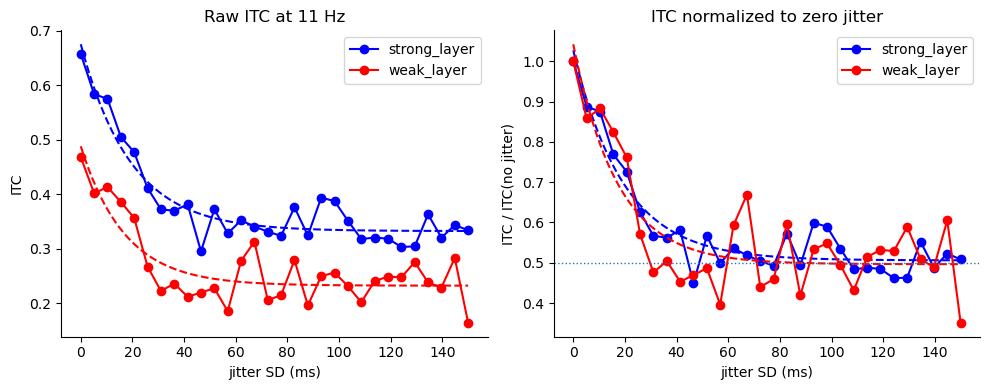

In [33]:
# -----------------------------
# Signal generation
# -----------------------------

def gaussian_kernel(fs, sigma_ms, area=1.0, half_width_sigma=6):
    sigma = sigma_ms / 1000
    kt = np.arange(-half_width_sigma * sigma,
                   half_width_sigma * sigma + 1 / fs,
                   1 / fs)
    h = np.exp(-0.5 * (kt / sigma) ** 2)
    h *= area / (h.sum() / fs)
    return h


def make_jittered_onsets(
    f0,
    dur,
    jitter_sd,
    t0=1.0,
    t1_margin=1.0,
    rng=None,
    min_isi=0.005,
):
    """
    Stimulus onset sequence with SOA ~ Normal(1/f0, jitter_sd).
    Negative/too-small SOAs are resampled.
    """
    rng = np.random.default_rng(rng)
    T = 1 / f0

    times = [t0]
    while True:
        if jitter_sd == 0:
            isi = T
        else:
            isi = rng.normal(T, jitter_sd)
            for _ in range(100):
                if isi >= min_isi:
                    break
                isi = rng.normal(T, jitter_sd)
            isi = max(isi, min_isi)

        nxt = times[-1] + isi
        if nxt > dur - t1_margin:
            break
        times.append(nxt)

    return np.asarray(times)


def make_train_signal(stim_times, fs, dur, sigma_ms=8, area=1.0):
    t = np.arange(0, dur, 1 / fs)
    impulses = np.zeros_like(t)

    stim_idx = np.round(stim_times * fs).astype(int)
    stim_idx = stim_idx[(stim_idx >= 0) & (stim_idx < len(t))]
    impulses[stim_idx] = 1.0

    h = gaussian_kernel(fs, sigma_ms=sigma_ms, area=area)
    x = fftconvolve(impulses, h, mode="same")
    return x, stim_idx


def simulate_two_layer_dataset(
    *,
    fs=1000,
    dur=8.0,
    f0=11.0,
    jitter_sds=(0.00, 0.04, 0.08, 0.12),
    n_trials=40,
    stim_sigma_ms=8,
    layer_gains=None,
    noise_rms=50.0,
    seed=1,
):
    """
    Returns data[jitter_sd]["signals"][layer] with shape (trial, time),
    and data[jitter_sd]["stim_idx"] as a list of onset-index arrays.
    """
    if layer_gains is None:
        layer_gains = {
            "strong_layer": 1.0,
            "weak_layer": 0.25,
        }

    rng = np.random.default_rng(seed)
    data = {}

    for jitter_sd in jitter_sds:
        signals = {layer: [] for layer in layer_gains}
        stim_idx_trials = []

        for _ in range(n_trials):
            stim_times = make_jittered_onsets(
                f0=f0,
                dur=dur,
                jitter_sd=jitter_sd,
                rng=rng,
                min_isi=0.005,
            )

            clean, stim_idx = make_train_signal(
                stim_times,
                fs=fs,
                dur=dur,
                sigma_ms=stim_sigma_ms,
                area=1.0,
            )

            stim_idx_trials.append(stim_idx)

            for layer, gain in layer_gains.items():
                noise = rng.normal(0, noise_rms, size=clean.shape)
                x = gain * clean + noise
                signals[layer].append(x)

        data[jitter_sd] = {
            "signals": {k: np.stack(v, axis=0) for k, v in signals.items()},
            "stim_idx": stim_idx_trials,
        }

    return data


# -----------------------------
# Morlet phase and ITC
# -----------------------------

def morlet_at_frequency(x, f, fs, n_cycles=5):
    sigma_t = n_cycles / (2 * np.pi * f)
    wt = np.arange(-4 * sigma_t, 4 * sigma_t + 1 / fs, 1 / fs)

    psi = np.exp(2j * np.pi * f * wt) * np.exp(-0.5 * (wt / sigma_t) ** 2)
    psi /= np.sqrt(np.sum(np.abs(psi) ** 2))

    return fftconvolve(x, np.conj(psi[::-1]), mode="same")


def rayleigh_p_from_R(R, n):
    """
    Rayleigh test approximation for non-uniform circular phase distribution.
    R is resultant length, n is number of phase samples.
    """
    z = n * R**2

    if n < 50:
        p = np.exp(np.sqrt(1 + 4*n + 4*(n*n - z*z)) - (1 + 2*n))
    else:
        p = np.exp(-z) * (
            1
            + (2*z - z*z) / (4*n)
            - (24*z - 132*z*z + 76*z**3 - 9*z**4) / (288*n*n)
        )

    return float(np.clip(p, 0, 1))


def rayleigh_p(phases):
    phases = np.asarray(phases)
    R = np.abs(np.mean(np.exp(1j * phases)))
    return rayleigh_p_from_R(R, len(phases))


def rayleigh_rcrit(n, alpha=0.05):
    """
    ITC threshold corresponding approximately to Rayleigh p=alpha.
    """
    return brentq(lambda R: rayleigh_p_from_R(R, n) - alpha, 0, 1 - 1e-12)


def fdr_bh(pvals, alpha=0.05):
    p = np.asarray(pvals, dtype=float)
    shape = p.shape
    flat = p.ravel()

    order = np.argsort(flat)
    ranked = flat[order]
    m = len(flat)

    passed = ranked <= alpha * np.arange(1, m + 1) / m
    sig = np.zeros(m, dtype=bool)

    if np.any(passed):
        k = np.max(np.where(passed)[0])
        sig[order[:k + 1]] = True

    return sig.reshape(shape)


def calc_itc_for_dataset(
    data,
    *,
    fs,
    f0,
    n_cycles=5,
    sample_mode="one_per_trial",
    alpha=0.05,
):
    """
    sample_mode:
      "one_per_trial" - take the middle valid stimulus onset from each trial.
                        This keeps n ~ number of trials, closer to a strict
                        across-trial ITC estimate.
      "all_events"    - pool all stimulus onsets across trials. This gives
                        smoother ITC but can make significance trivial.
    """
    rows = []

    edge = int(np.ceil(4 * (n_cycles / (2 * np.pi * f0)) * fs))

    for jitter_sd, cond in data.items():
        stim_idx_trials = cond["stim_idx"]

        for layer, X in cond["signals"].items():
            phases = []

            for x, stim_idx in zip(X, stim_idx_trials):
                W = morlet_at_frequency(x, f0, fs, n_cycles=n_cycles)

                valid = stim_idx[
                    (stim_idx >= edge) &
                    (stim_idx < len(x) - edge)
                ]

                if len(valid) == 0:
                    continue

                if sample_mode == "one_per_trial":
                    valid = np.asarray([valid[len(valid) // 2]])
                elif sample_mode == "all_events":
                    pass
                else:
                    raise ValueError("sample_mode must be 'one_per_trial' or 'all_events'")

                phases.append(np.angle(W[valid]))

            phases = np.concatenate(phases)
            ITC = np.abs(np.mean(np.exp(1j * phases)))

            rows.append({
                "layer": layer,
                "jitter_sd": jitter_sd,
                "ITC": ITC,
                "n_phase_samples": len(phases),
                "p_rayleigh": rayleigh_p(phases),
                "Rcrit_p05": rayleigh_rcrit(len(phases), alpha=alpha),
            })

    df = pd.DataFrame(rows).sort_values(["layer", "jitter_sd"]).reset_index(drop=True)

    # FDR across all layer x jitter tests in this toy example.
    df["significant_fdr"] = fdr_bh(df["p_rayleigh"].to_numpy(), alpha=alpha)

    # Normalize to zero-jitter condition within each layer.
    df["ITC_norm"] = df.groupby("layer")["ITC"].transform(lambda y: y / y.iloc[0])

    return df


# -----------------------------
# Fits and tolerance estimates
# -----------------------------

def exp_decay(x, floor, amp, tau):
    return floor + amp * np.exp(-x / tau)


def fit_exp_decay(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    floor0 = max(0, 0.8 * np.nanmin(y))
    amp0 = max(1e-6, y[0] - floor0)
    tau0 = 0.05

    try:
        popt, _ = curve_fit(
            exp_decay,
            x,
            y,
            p0=(floor0, amp0, tau0),
            bounds=([0, 0, 1e-4], [1, 2, 10]),
            maxfev=10000,
        )
    except RuntimeError:
        popt = np.array([np.nan, np.nan, np.nan])

    return popt


def crossing_x_for_exp_decay(params, ycrit):
    floor, amp, tau = params

    if not np.all(np.isfinite(params)) or amp <= 0 or tau <= 0:
        return np.nan

    # Curve starts below criterion.
    if floor + amp < ycrit:
        return 0.0

    # Curve never falls below criterion.
    if floor >= ycrit:
        return np.inf

    return float(-tau * np.log((ycrit - floor) / amp))


def summarize_jitter_tolerance(df):
    rows = []

    for layer, g in df.groupby("layer"):
        g = g.sort_values("jitter_sd")

        raw_params = fit_exp_decay(g["jitter_sd"], g["ITC"])
        norm_params = fit_exp_decay(g["jitter_sd"], g["ITC_norm"])

        # Discrete tolerance: largest tested jitter with significant ITC.
        sig_jitters = g.loc[g["significant_fdr"], "jitter_sd"]
        discrete_tol = float(sig_jitters.max()) if len(sig_jitters) else np.nan

        # Fitted tolerance: crossing of raw-ITC fit with Rayleigh p=0.05 threshold.
        # Here I use median Rcrit across jitter conditions for that layer.
        rcrit = float(g["Rcrit_p05"].median())
        fitted_tol = crossing_x_for_exp_decay(raw_params, rcrit)

        # 50% normalized drop, analogous to the dotted-line visualization.
        j50 = crossing_x_for_exp_decay(norm_params, 0.5)

        rows.append({
            "layer": layer,
            "raw_floor": raw_params[0],
            "raw_amp": raw_params[1],
            "raw_tau": raw_params[2],
            "norm_floor": norm_params[0],
            "norm_amp": norm_params[1],
            "norm_tau": norm_params[2],
            "jitter_tolerance_discrete": discrete_tol,
            "jitter_tolerance_fit": fitted_tol,
            "j50_norm_fit": j50,
        })

    return pd.DataFrame(rows)


# -----------------------------
# Run demo
# -----------------------------

fs = 500
f0 = 11.0          # fixed repetition rate; change to 1.6 or 6 if needed
dur = 8.0

data = simulate_two_layer_dataset(
    fs=fs,
    dur=dur,
    f0=f0,
    jitter_sds=np.linspace(0, 0.15, 30),
    n_trials=500,
    stim_sigma_ms=15,
    layer_gains={
        "strong_layer": 0.6,
        "weak_layer": 0.4,
    },
    noise_rms=50.0,
    seed=1,
)

df = calc_itc_for_dataset(
    data,
    fs=fs,
    f0=f0,
    n_cycles=5,
    sample_mode="one_per_trial",   # start here
    alpha=0.05,
)

summary = summarize_jitter_tolerance(df)

# -----------------------------
# Plot
# -----------------------------

jgrid = np.linspace(0, df["jitter_sd"].max(), 200)
colors = ['b', 'r', 'g']

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)


for n, (layer, g) in enumerate(df.groupby("layer")):
    g = g.sort_values("jitter_sd")

    raw_params = fit_exp_decay(g["jitter_sd"], g["ITC"])
    norm_params = fit_exp_decay(g["jitter_sd"], g["ITC_norm"])

    col = colors[n]
    axes[0].plot(g["jitter_sd"] * 1000, g["ITC"], f'{col}o-', label=layer)
    axes[0].plot(jgrid * 1000, exp_decay(jgrid, *raw_params), f'{col}--')

    axes[1].plot(g["jitter_sd"] * 1000, g["ITC_norm"], f'{col}o-', label=layer)
    axes[1].plot(jgrid * 1000, exp_decay(jgrid, *norm_params), f'{col}--')

axes[0].set_title(f"Raw ITC at {f0:g} Hz")
axes[0].set_xlabel("jitter SD (ms)")
axes[0].set_ylabel("ITC")

axes[1].set_title("ITC normalized to zero jitter")
axes[1].set_xlabel("jitter SD (ms)")
axes[1].set_ylabel("ITC / ITC(no jitter)")
axes[1].axhline(0.5, linestyle=":", linewidth=1)

for ax in axes:
    ax.legend()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()